# DeepHEx tutorial: Visium HD

This notebook walks through the complete Visium HD workflow: binned HD input, histology feature extraction, initial high-resolution interpolation, BCAF reconstruction, export, and ground-truth comparison.

The default path reuses the released, preprocessed mouse-brain demo and its trained checkpoint. It therefore performs inference without repeating the 400-epoch training run. Set `RUN_PREPROCESSING`, `RUN_UNI_FEATURES` and `RUN_INTERPOLATION` to `True` to rebuild those stages from the original files, or set `REUSE_CHECKPOINT = False` to train a new model.

## 1. Paths and GPU assignment

In [ ]:
from pathlib import Path
import os
import sys

os.environ['CUDA_VISIBLE_DEVICES'] = '1'

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import Image as NotebookImage, display
import matplotlib.pyplot as plt
import torch

HD_DATA_DIR = Path.home() / 'DeepHEx_data' / 'visium_hd_mouse_brain_demo'
WORK_DIR = HD_DATA_DIR
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'pipeline.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

assert os.environ['CUDA_VISIBLE_DEVICES'] == '1'
assert torch.cuda.is_available(), 'CUDA is required for this tutorial'
assert torch.cuda.device_count() == 1, 'Only physical GPU 1 should be visible'
print(f"Project: ~/{PROJECT_ROOT.relative_to(Path.home())}")
print(f"Visium HD example: ~/{HD_DATA_DIR.relative_to(Path.home())}")
print(f"Visible GPU: logical cuda:0 -> physical GPU 1 ({torch.cuda.get_device_name(0)})")

Project: ~/DeepHEx
Visium HD example: ~/DeepHEx_data/visium_hd_mouse_brain_demo
Visible GPU: logical cuda:0 -> physical GPU 1 (NVIDIA A100 80GB PCIe)


## 2. Validate the preprocessed HD inputs

In [2]:
required_files = {
    'binned HD matrix': HD_DATA_DIR / 'square_008um' / 'filtered_feature_bc_matrix.h5',
    'histology image': HD_DATA_DIR / 'he.jpg',
    'pseudo-Visium counts': HD_DATA_DIR / 'cnts.csv',
    'pseudo-Visium locations': HD_DATA_DIR / 'locs.csv',
    'gene panel': HD_DATA_DIR / 'gene-names.txt',
    'superpixel mask': HD_DATA_DIR / 'mask.png',
    'interpolated counts': HD_DATA_DIR / 'HRcnts.csv',
    'interpolated locations': HD_DATA_DIR / 'HRlocs.csv',
    'UNI feature map': HD_DATA_DIR / 'Histology_feature_map.pickle',
    'HD ground truth': HD_DATA_DIR / 'genes_3D.pkl',
    'BCAF checkpoint': HD_DATA_DIR / 'states' / '00' / 'model.pt',
}
missing = [f"{label}: {path.name}" for label, path in required_files.items() if not path.is_file()]
assert not missing, 'Missing tutorial inputs:\n' + '\n'.join(missing)

counts = pd.read_csv(HD_DATA_DIR / 'cnts.csv', index_col=0)
locs = pd.read_csv(HD_DATA_DIR / 'locs.csv', index_col=0)
mask = np.asarray(Image.open(HD_DATA_DIR / 'mask.png'))[..., 0] > 0
genes = [line.strip() for line in (HD_DATA_DIR / 'gene-names.txt').read_text().splitlines() if line.strip()]
assert counts.index.equals(locs.index)
assert counts.shape == (len(locs), len(genes))
assert mask.shape == (826, 658)

print(f"Pseudo-Visium spots: {counts.shape[0]:,}")
print(f"Selected genes: {counts.shape[1]:,}")
print(f"Superpixel grid: {mask.shape[0]} x {mask.shape[1]}")
print(f"Tissue superpixels: {int(mask.sum()):,}")

Pseudo-Visium spots: 2,527
Selected genes: 1,000
Superpixel grid: 826 x 658
Tissue superpixels: 396,019


## 3. Quality control: histology, spot layout and tissue mask

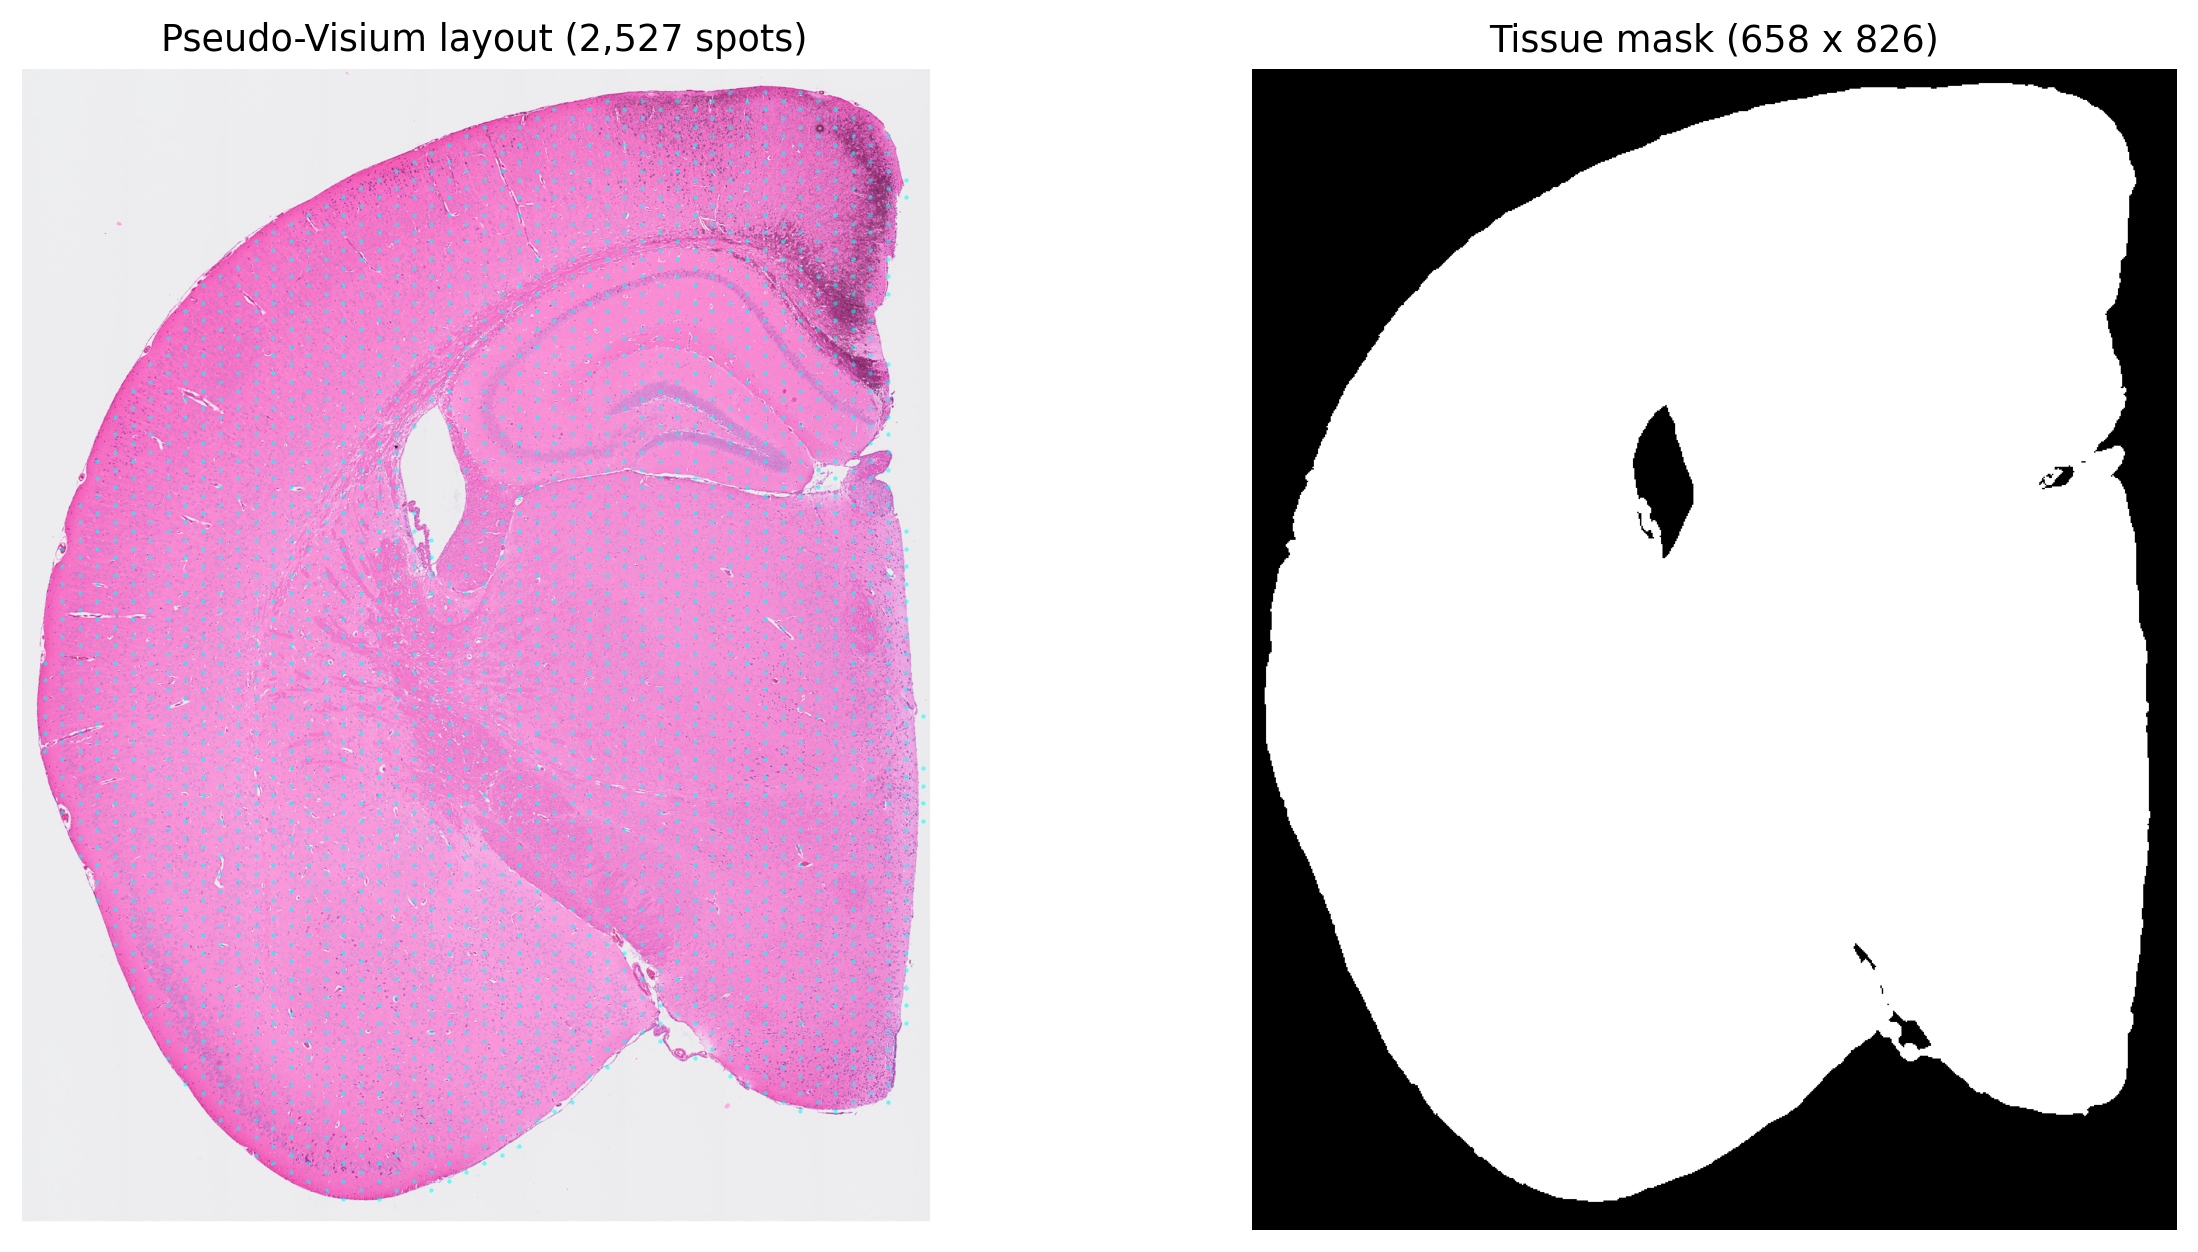

In [3]:
Image.MAX_IMAGE_PIXELS = 900_000_000
image = Image.open(HD_DATA_DIR / 'he.jpg').convert('RGB')
original_size = image.size
image.thumbnail((1800, 1800))
preview = np.asarray(image)
scale_x = original_size[0] / image.size[0]
scale_y = original_size[1] / image.size[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
axes[0].imshow(preview)
axes[0].scatter(locs['x'] / scale_x, locs['y'] / scale_y, s=2, c='cyan', alpha=0.55, linewidths=0)
axes[0].set_title(f'Pseudo-Visium layout ({len(locs):,} spots)')
axes[0].axis('off')
axes[1].imshow(mask, cmap='gray')
axes[1].set_title(f'Tissue mask ({mask.shape[1]} x {mask.shape[0]})')
axes[1].axis('off')
fig.tight_layout()
qc_path = WORK_DIR / 'figures' / 'visium_hd_qc.png'
qc_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(qc_path, dpi=220, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(qc_path)))

## 4. Reproducible configuration

In [4]:
import yaml

REUSE_CHECKPOINT = True
RUN_PREPROCESSING = False
RUN_UNI_FEATURES = False
RUN_INTERPOLATION = False
RECOMPUTE_METRICS = False

CONFIG = {
    'global': {
        'input_type': 'visium_hd',
        'directory': str(WORK_DIR) + '/',
        'pseudo_radius': 55,
        'superpixel_size': 16,
        'seed': 42,
    },
    'histology': {'token_env': 'HF_TOKEN', 'model_name': 'UNI'},
    'train': {
        'epochs': 0 if REUSE_CHECKPOINT else 400,
        'device': 'cuda',
        'gpu_ids': [0],
        'n_states': 1,
        'BCAF_embeddings': 256,
        'k_neighbors': 6,
        'learning_rate': 1e-4,
        'batch_size': 'auto',
        'load_saved': REUSE_CHECKPOINT,
        'enhance': True,
    },
    'preprocessing': {
        'visium_hd': {
            'sample_size': 'square_008um',
            'raw_image_name': 'Visium_HD_Mouse_Brain_tissue_image.tif',
            'output_image_name': 'he.jpg',
            'gene_names_name': 'gene-names.txt',
            'ground_truth': 'genes_3D.pkl',
            'scale_pix_size': 0.5,
            'num_top_genes': 1000,
        }
    },
    'export': {
        'enabled': True,
        'h5ad_name': 'deephex_expression.h5ad',
        'csv': False,
        'csv_name': 'deephex_expression.csv',
        'metadata_name': 'run_metadata.json',
    },
}
config_path = WORK_DIR / 'deephex_visium_hd_tutorial_config.yaml'
config_path.write_text(yaml.safe_dump(CONFIG, sort_keys=False), encoding='utf-8')
if REUSE_CHECKPOINT:
    assert (WORK_DIR / 'states' / '00' / 'model.pt').is_file(), 'Checkpoint not found; set REUSE_CHECKPOINT=False to train.'
print(f"Reuse checkpoint: {REUSE_CHECKPOINT}")
print(f"Training epochs: {CONFIG['train']['epochs']}")
print(f"Logical GPU ids: {CONFIG['train']['gpu_ids']}")

Reuse checkpoint: True
Training epochs: 0
Logical GPU ids: [0]


## 5. Optional rebuild stages

In [5]:
if RUN_PREPROCESSING:
    from data import run_visium_hd_preprocessing
    preprocessing_result = run_visium_hd_preprocessing(CONFIG)
    print('Preprocessing finished')

if RUN_UNI_FEATURES:
    from model.histology_ext import run_feature_extraction
    uni_result = run_feature_extraction(CONFIG)
    print('UNI feature extraction finished')

if RUN_INTERPOLATION:
    from model.GetHr import run_get_hr
    run_get_hr(CONFIG)
    print('High-resolution interpolation finished')

print('Skipped stages:', [name for name, enabled in {
    'preprocessing': RUN_PREPROCESSING,
    'UNI features': RUN_UNI_FEATURES,
    'interpolation': RUN_INTERPOLATION,
}.items() if not enabled])

Skipped stages: ['preprocessing', 'UNI features', 'interpolation']


## 6. Load the checkpoint and reconstruct expression

Set `REUSE_CHECKPOINT=False` only when you intend to train a new model.

In [6]:
from pipeline import run_main

torch.cuda.reset_peak_memory_stats()
run_metadata = run_main(CONFIG, write_exports=True)
print('Expression dimensions:', run_metadata['dimensions']['expression_matrix'])
print('Peak CUDA memory (MB):', round(run_metadata['resources']['peak_cuda_memory_mb'], 1))

~/miniconda3/envs/cccphe/lib/python3.11/site-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)


~/miniconda3/envs/cccphe/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


~/miniconda3/envs/cccphe/lib/python3.11/site-packages/transformers/utils/generic.py:441: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


Global seed set to 42


x: (826, 658, 1024) , y: (2527, 1000)


~/miniconda3/envs/cccphe/lib/python3.11/site-packages/pytorch_lightning/utilities/migration/utils.py:49: PossibleUserWarning: The loaded checkpoint was produced with Lightning v2.5.5, which is newer than your current Lightning version: v1.9.5
  rank_zero_warn(


Model loaded from ~/DeepHEx_data/visium_hd_mouse_brain_demo/states/00/model.pt


~/DeepHEx/pipeline.py:158: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:274.)
  x = torch.tensor(x, device=model.device)


All genes have been saved in ~/DeepHEx_data/visium_hd_mouse_brain_demo/cnts-super/..


Exported DeepHEx results: 396019 superpixels x 1000 genes to ~/DeepHEx_data/visium_hd_mouse_brain_demo/deephex_expression.h5ad
Expression dimensions: [396019, 1000]
Peak CUDA memory (MB): 230.1


## 7. Load and inspect the exported result

In [7]:
import anndata as ad

result = ad.read_h5ad(WORK_DIR / 'deephex_expression.h5ad', backed='r')
assert result.shape == (int(mask.sum()), len(genes))
print(result)
display(result.obs.head())

AnnData object with n_obs × n_vars = 396019 × 1000 backed at '~/DeepHEx_data/visium_hd_mouse_brain_demo/deephex_expression.h5ad'
    obs: 'superpixel_row', 'superpixel_col', 'x', 'y', 'x_um', 'y_um'
    uns: 'deephex'


,superpixel_row,superpixel_col,x,y,x_um,y_um
spatial_id,,,,,,
superpixel_10_517,10,517,8280.0,168.0,4140.0,84.0
superpixel_10_518,10,518,8296.0,168.0,4148.0,84.0
superpixel_10_519,10,519,8312.0,168.0,4156.0,84.0
superpixel_10_520,10,520,8328.0,168.0,4164.0,84.0
superpixel_10_521,10,521,8344.0,168.0,4172.0,84.0


## 8. Ground-truth and DeepHEx expression maps

Visualized genes: Olfm1, Hpca


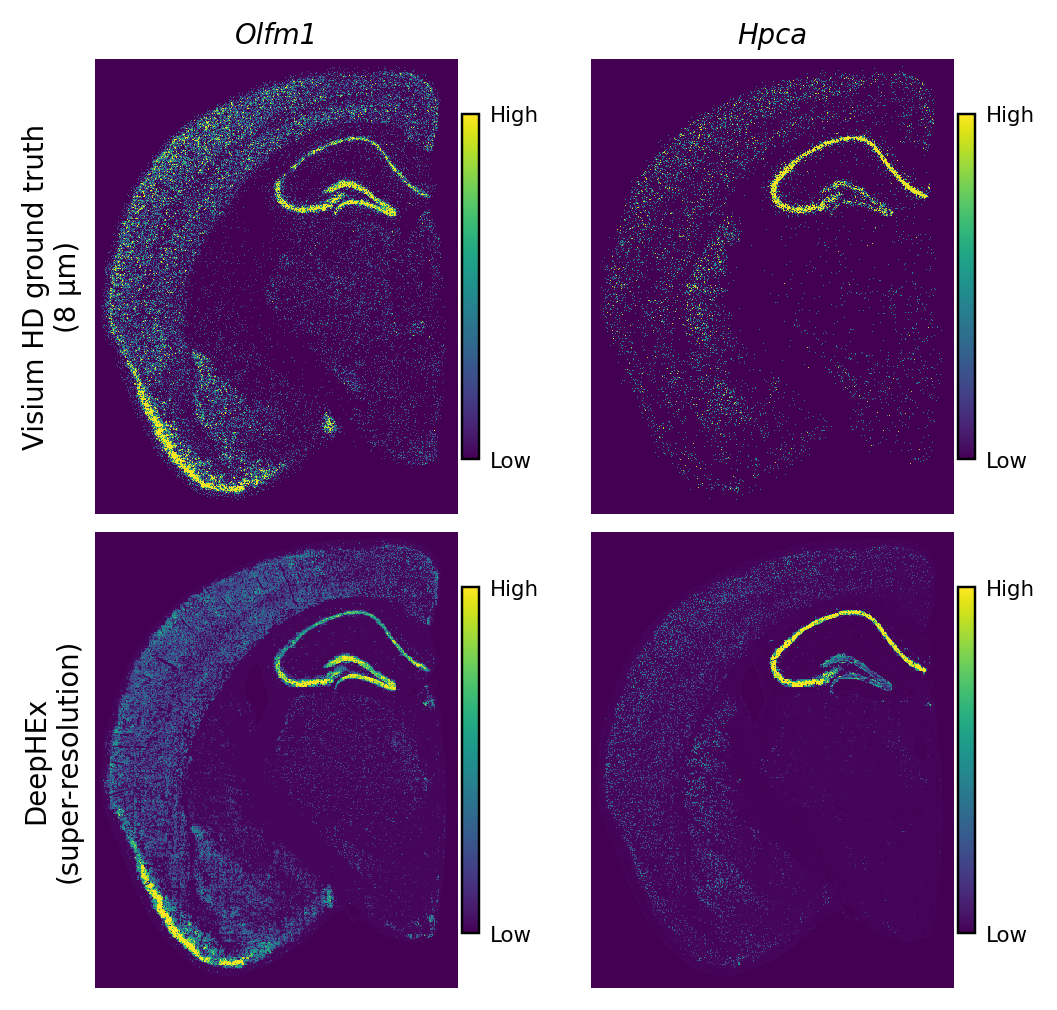

Editable vector: ~/DeepHEx_data/visium_hd_mouse_brain_demo/figures/visium_hd_expression_maps.svg


In [4]:
from utils.visualization import load_visium_hd_ground_truth, plot_visium_hd_expression

ground_truth = load_visium_hd_ground_truth(HD_DATA_DIR / 'genes_3D.pkl')
hd_expression_fig, hd_genes, hd_expression_paths = plot_visium_hd_expression(
    WORK_DIR,
    ground_truth,
    requested_genes=('Olfm1', 'Hpca'),
    fallback_genes=('Snap25', 'Slc17a7', 'Pcp4', 'Mbp'),
)
display(NotebookImage(filename=hd_expression_paths['png']))
print('Editable vector:', '~/DeepHEx_data/visium_hd_mouse_brain_demo/figures/visium_hd_expression_maps.svg')
plt.close(hd_expression_fig)

## 9. DeepHEx-only evaluation against Visium HD ground truth

In [5]:
from utils.visualization import compute_visium_hd_metrics

metrics_path = WORK_DIR / 'visium_hd_metrics.csv'
expected_columns = ['gene', 'rmse', 'mae', 'ssim']
needs_recompute = RECOMPUTE_METRICS or not metrics_path.is_file()
if not needs_recompute:
    existing_metrics = pd.read_csv(metrics_path, nrows=0)
    needs_recompute = list(existing_metrics.columns) != expected_columns

if needs_recompute:
    hd_metrics = compute_visium_hd_metrics(WORK_DIR, ground_truth)
    hd_metrics.to_csv(metrics_path, index=False)
    print(f'Computed normalized metrics for {len(hd_metrics):,} genes')
else:
    hd_metrics = pd.read_csv(metrics_path)
    print(f'Loaded existing normalized metrics for {len(hd_metrics):,} genes')
assert len(hd_metrics) == len(genes)
hd_metrics.describe().T

Computed normalized metrics for 1,000 genes


,count,mean,std,min,25%,50%,75%,max
rmse,1000.0,0.012051,0.012447,0.001777,0.003273,0.005479,0.017480,0.054663
mae,1000.0,0.002810,0.005522,0.000005,0.000042,0.000194,0.002532,0.033851
ssim,1000.0,0.929332,0.115452,0.532033,0.904582,0.995349,0.998704,0.999806


## 10. Metric distributions for DeepHEx

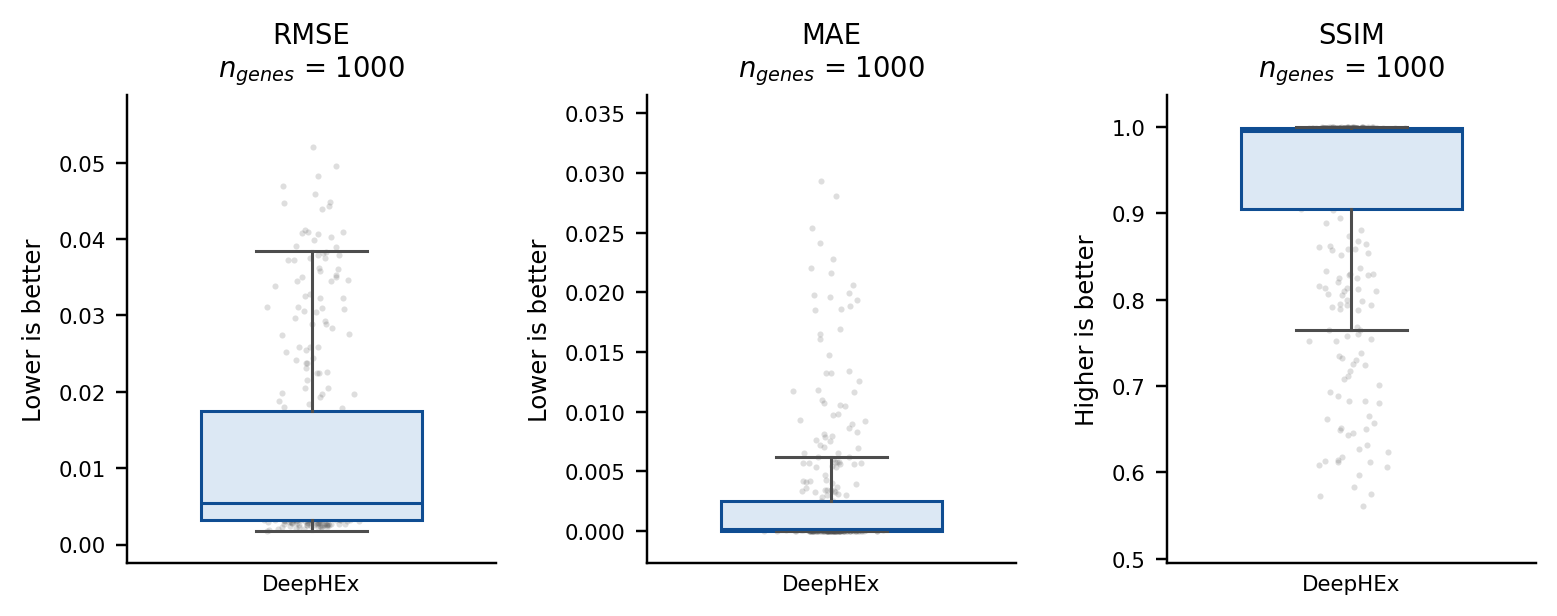

Gene-level metric table: visium_hd_metrics.csv
Editable vector: ~/DeepHEx_data/visium_hd_mouse_brain_demo/figures/visium_hd_metric_boxplots.svg


In [6]:
from utils.visualization import plot_metric_boxplots

metric_fig, metric_paths = plot_metric_boxplots(
    hd_metrics,
    columns=('rmse', 'mae', 'ssim'),
    titles=('RMSE', 'MAE', 'SSIM'),
    direction=('Lower is better', 'Lower is better', 'Higher is better'),
    output_stem=WORK_DIR / 'figures' / 'visium_hd_metric_boxplots',
)
display(NotebookImage(filename=metric_paths['png']))
print('Gene-level metric table: visium_hd_metrics.csv')
print('Editable vector: ~/DeepHEx_data/visium_hd_mouse_brain_demo/figures/visium_hd_metric_boxplots.svg')
plt.close(metric_fig)
del ground_truth

## 11. Output checklist

- `deephex_expression.h5ad`: superpixels × genes with spatial coordinates in `obs`.
- `deephex_coordinates.csv`: row/column indices and image/physical coordinates.
- `cnts-super/*.pickle`: one reconstructed 2-D map per gene.
- `visium_hd_metrics.csv`: gene-wise RMSE, MAE and SSIM computed from jointly `[0, 1]`-normalized expression.
- `figures/visium_hd_qc.png`: image, pseudo-Visium layout and tissue-mask QC.
- `figures/visium_hd_expression_maps.{svg,pdf,tiff,png}`: matched ground-truth and DeepHEx maps.
- `figures/visium_hd_metric_boxplots.{svg,pdf,tiff,png}`: DeepHEx-only metric distributions.
- `run_metadata.json`: parameters, seeds, software versions and resource measurements.

## Command-line equivalent

After setting `WORK_DIR` and the input options in a YAML file:

```bash
CUDA_VISIBLE_DEVICES=1 python interface.py \
  --config deephex_visium_hd_tutorial_config.yaml \
  --input-type visium_hd
```

For checkpoint-only inference, use the same configuration with `epochs: 0` and `load_saved: true`.